# 02 - Risque de retard de livraison

**Question métier** : au moment où une commande est passée, quelle est la probabilité qu'elle arrive **en retard** ?
L'objectif est de déclencher une action préventive (prévenir le client, surclasser le transport...).

**Protocole**
- Unité : la **commande** (la cible est identique pour toutes ses lignes ; modéliser à la ligne dupliquerait les exemples).
- Uniquement les variables **connues à la commande** (liste justifiée en section 1).
- Commandes **expédiées** uniquement : une commande annulée n'a pas de délai de livraison.
- Découpage **temporel** : train 2015-2016 -> validation S1 2017 (choix des hyperparamètres et du seuil) -> test 01/07/2017-31/01/2018 (évalué **une seule fois**).
- Baseline « métier » (règle par mode d'expédition), puis régression logistique, puis XGBoost.

In [1]:
import sys, warnings
from pathlib import Path

RACINE = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RACINE))
warnings.filterwarnings("ignore", category=FutureWarning)

import itertools
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.metrics import ConfusionMatrixDisplay, roc_auc_score, roc_curve

from src.config import SEED, SQL_DIR, set_seed
from src.etl.load import copier_dataframe, creer_moteur, executer_script_sql
from src.models import risque as R

set_seed()
pd.set_option("display.width", 160)
BLEU, ORANGE, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#52514e"
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c8c7c2", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.labelcolor": GRIS, "xtick.color": GRIS, "ytick.color": GRIS,
})
engine = creer_moteur()

C:\ENSA\Achraf\cv\CV\power BI\supply-pulse\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Variables : ce qui est connu au moment de la commande

Revue **colonne par colonne** de l'entrepôt (le README reprend ce tableau).

| Colonne (entrepôt) | Décision | Justification |
|---|---|---|
| `jours_reels`, `ecart_jours` | **exclue** | mesurée après livraison ; la cible en est directement calculée |
| `statut_livraison` | **exclue** | contient la réponse (`Late delivery`...) |
| `horodatage_expedition`, `date_expedition_id` | **exclue** | connue seulement à l'expédition, après la commande |
| `statut_commande` | **exclue** | évolue après la commande (`COMPLETE`, `CLOSED`) ; `CANCELED`/`SUSPECTED_FRAUD` = 0 % de retard (01_eda) |
| `est_annulee` | **filtre** uniquement | l'annulation n'est pas connue à la commande ; sert à retirer les commandes non expédiées |
| `profit`, `ratio_profit` | `ratio_profit_moyen` gardé | marge définie par le prix et le coût produit, connus à la commande |
| `ligne_id`, `commande_id`, `client_id`, `produit_id` | exclues | identifiants : aucune information généralisable, risque de sur-apprentissage |
| `mode_expedition` (et `jours_prevus`, équivalent) | gardée | choisie par le client à la commande |
| `marche`, `region` (destination) | gardées | adresse de livraison connue à la commande |
| `pays`, `ville`, `etat` de destination | exclues | 164 pays / 3 600 villes : trop fines, déjà résumées par la région |
| `segment`, `client_pays` | gardées | attributs du client |
| `type_paiement` | gardée | choisi à la commande |
| catégorie / département | gardés (catégorie principale de la commande) | contenu du panier |
| quantité, montants, remise, prix | agrégés par commande | contenu du panier |
| `horodatage_commande` | heure, jour de semaine, mois, week-end | connus à la commande ; la date sert aussi au découpage |

In [2]:
commandes = R.ajouter_variables_temporelles(R.charger_commandes(engine))
print("Commandes :", len(commandes))
print("Variables du modèle :", R.VARIABLES)

expediees = commandes[commandes["est_annulee"] == 0].copy()
expediees["jeu"] = R.attribuer_jeu(expediees["horodatage_commande"])
print("Commandes annulées retirées :", len(commandes) - len(expediees))

resume = expediees.groupby("jeu", sort=False).agg(
    debut=("horodatage_commande", "min"), fin=("horodatage_commande", "max"),
    commandes=("commande_id", "size"), taux_retard=("est_en_retard", "mean")).round(3)
resume

Commandes : 65752
Variables du modèle : ['mode_expedition', 'marche', 'region', 'segment', 'client_pays', 'type_paiement', 'categorie_principale', 'departement_principal', 'nb_lignes', 'quantite_totale', 'montant_net_total', 'taux_remise_moyen', 'ratio_profit_moyen', 'prix_max', 'heure', 'jour_semaine', 'mois', 'est_weekend']
Commandes annulées retirées : 2855


,debut,fin,commandes,taux_retard
jeu,,,,
train,2015-01-01 00:00:00,2016-12-31 23:51:00,39950,0.574
validation,2017-01-01 00:33:00,2017-06-30 23:25:00,9876,0.567
test,2017-07-01 00:07:00,2018-01-31 23:38:00,13071,0.576


In [3]:
train, valid, test = (expediees[expediees["jeu"] == j] for j in ("train", "validation", "test"))
X = lambda d: d[R.VARIABLES]
y = lambda d: d[R.CIBLE]

## 2. Baseline : règle par mode d'expédition

La probabilité de retard est le taux de retard observé de chaque mode sur le train. C'est ce qu'un responsable logistique ferait sans modèle.

In [4]:
regle = R.RegleParMode().fit(X(train), y(train))
display((regle.taux_ * 100).round(1).rename("taux de retard train (%)").to_frame())
auc_val = {"Règle par mode": roc_auc_score(y(valid), regle.predict_proba(X(valid))[:, 1])}
print(f"ROC-AUC validation : {auc_val['Règle par mode']:.4f}")

,taux de retard train (%)
First Class,100.0
Same Day,46.1
Second Class,80.1
Standard Class,40.1


ROC-AUC validation : 0.7384


## 3. Régression logistique (baseline statistique)

In [5]:
resultats_lr = {}
for C in [0.01, 0.1, 1.0, 10.0]:
    m = R.creer_regression_logistique(C).fit(X(train), y(train))
    resultats_lr[C] = roc_auc_score(y(valid), m.predict_proba(X(valid))[:, 1])
display(pd.Series(resultats_lr, name="ROC-AUC validation").rename_axis("C").round(4).to_frame())
meilleur_C = max(resultats_lr, key=resultats_lr.get)
auc_val["Régression logistique"] = resultats_lr[meilleur_C]
print("C retenu :", meilleur_C)

,ROC-AUC validation
C,
0.01,0.7395
0.10,0.7432
1.00,0.7444
10.00,0.7446


C retenu : 10.0


## 4. XGBoost

Petite grille (8 combinaisons) évaluée sur la validation. Une grille plus large n'aurait pas de sens au vu du faible signal (01_eda).

In [6]:
grille = []
for profondeur, taux, n_arbres in itertools.product([3, 5], [0.05, 0.1], [200, 500]):
    m = R.creer_xgboost(max_depth=profondeur, learning_rate=taux, n_estimators=n_arbres).fit(X(train), y(train))
    grille.append({"max_depth": profondeur, "learning_rate": taux, "n_estimators": n_arbres,
                   "roc_auc_val": roc_auc_score(y(valid), m.predict_proba(X(valid))[:, 1])})
grille = pd.DataFrame(grille).sort_values("roc_auc_val", ascending=False).reset_index(drop=True)
display(grille.round(4))
params_xgb = grille.iloc[0][["max_depth", "learning_rate", "n_estimators"]].to_dict()
params_xgb = {"max_depth": int(params_xgb["max_depth"]), "learning_rate": float(params_xgb["learning_rate"]),
              "n_estimators": int(params_xgb["n_estimators"])}
auc_val["XGBoost"] = grille.loc[0, "roc_auc_val"]
print("Hyperparamètres retenus :", params_xgb)

,max_depth,learning_rate,n_estimators,roc_auc_val
0,3,0.05,500,0.7728
1,3,0.10,200,0.7727
2,5,0.05,500,0.7722
3,3,0.10,500,0.7715
4,3,0.05,200,0.7708
5,5,0.05,200,0.7708
6,5,0.10,500,0.7705
7,5,0.10,200,0.7696


Hyperparamètres retenus : {'max_depth': 3, 'learning_rate': 0.05, 'n_estimators': 500}


## 5. Comparaison sur la validation

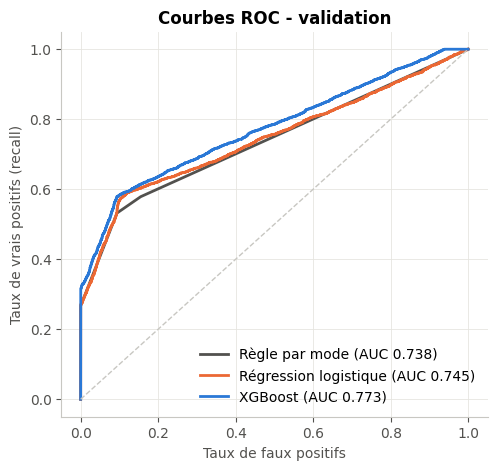

In [7]:
modeles_val = {
    "Règle par mode": regle,
    "Régression logistique": R.creer_regression_logistique(meilleur_C).fit(X(train), y(train)),
    "XGBoost": R.creer_xgboost(**params_xgb).fit(X(train), y(train)),
}
proba_val = {nom: m.predict_proba(X(valid))[:, 1] for nom, m in modeles_val.items()}

fig, ax = plt.subplots(figsize=(5.5, 5))
for (nom, p), couleur in zip(proba_val.items(), [GRIS, ORANGE, BLEU]):
    fpr, tpr, _ = roc_curve(y(valid), p)
    ax.plot(fpr, tpr, color=couleur, lw=2, label=f"{nom} (AUC {roc_auc_score(y(valid), p):.3f})")
ax.plot([0, 1], [0, 1], color="#c8c7c2", ls="--", lw=1)
ax.set(title="Courbes ROC - validation", xlabel="Taux de faux positifs", ylabel="Taux de vrais positifs (recall)")
ax.legend(loc="lower right", frameon=False)
plt.show()

## 6. Choix du seuil : un arbitrage métier

Rater un retard (faux négatif) coûte plus cher qu'une fausse alerte (faux positif).
**Hypothèse de travail, à faire valider par le métier** : un retard non anticipé coûte **4 fois** une fausse alerte (réclamation, geste commercial, risque de perte du client, contre un appel ou un surclassement inutile).

Le seuil est choisi en **minimisant le coût total sur la validation** (le test n'est pas utilisé). Quand plusieurs seuils sont équivalents, on prend le plus proche du seuil théorique.
Rappel théorique : avec des probabilités bien calibrées, il faut alerter dès que `p x C_FN > (1 - p) x C_FP`, soit `p > C_FP / (C_FP + C_FN)` = **0,20** pour un ratio de 4.

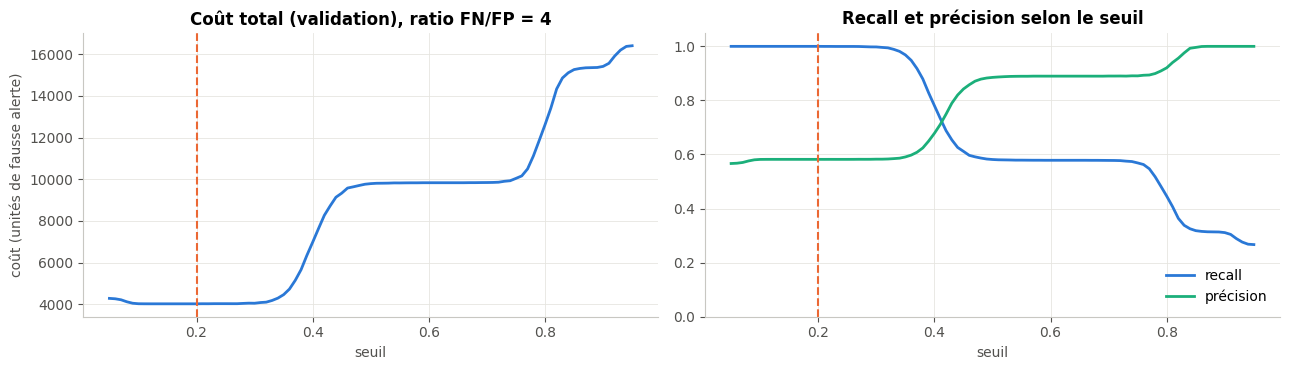

Seuils de coût minimal sur la validation : 0.12 à 0.20 (tous équivalents)
Seuil théorique C_FP/(C_FP+C_FN) : 0.20
Seuil retenu : 0.20 (le plus proche du seuil théorique dans la plage optimale)


In [8]:
COUTS = R.CoutsMetier(cout_fn=4.0, cout_fp=1.0)
p_val = proba_val["XGBoost"]
courbe = R.cout_par_seuil(y(valid), p_val, COUTS)
SEUIL = R.choisir_seuil(y(valid), p_val, COUTS)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(courbe["seuil"], courbe["cout"], color=BLEU, lw=2)
axes[0].axvline(SEUIL, color=ORANGE, ls="--", lw=1.5)
axes[0].set(title="Coût total (validation), ratio FN/FP = 4", xlabel="seuil", ylabel="coût (unités de fausse alerte)")
axes[1].plot(courbe["seuil"], courbe["recall"], color=BLEU, lw=2, label="recall")
axes[1].plot(courbe["seuil"], courbe["precision"], color=AQUA, lw=2, label="précision")
axes[1].axvline(SEUIL, color=ORANGE, ls="--", lw=1.5)
axes[1].set(title="Recall et précision selon le seuil", xlabel="seuil", ylim=(0, 1.05))
axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()
optimaux = courbe.loc[courbe["cout"] == courbe["cout"].min(), "seuil"]
print(f"Seuils de coût minimal sur la validation : {optimaux.min():.2f} à {optimaux.max():.2f} (tous équivalents)")
print(f"Seuil théorique C_FP/(C_FP+C_FN) : {R.seuil_theorique(COUTS):.2f}")
print(f"Seuil retenu : {SEUIL:.2f} (le plus proche du seuil théorique dans la plage optimale)")

In [9]:
# Pourquoi la courbe a des « marches » : les probabilités se regroupent par profil de commande.
profil = valid.assign(proba=p_val, apres_midi=valid["heure"] >= 12).groupby(
    ["mode_expedition", "apres_midi"]).agg(commandes=("proba", "size"), proba_moyenne=("proba", "mean"),
                                           taux_retard_reel=("est_en_retard", "mean")).round(3)
profil

commandes  proba_moyenne  taux_retard_reel
mode_expedition apres_midi                                            
First Class     False             767          0.999             1.000
                True              726          0.999             1.000
Same Day        False             262          0.077             0.000
                True              262          0.919             1.000
Second Class    False             909          0.792             0.784
                True              975          0.805             0.790
Standard Class  False            3011          0.390             0.396
                True             2964          0.407             0.393

In [10]:
# Sensibilité : le seuil et ses conséquences selon le ratio de coûts supposé.
sensibilite = []
for ratio in [1, 1.5, 2, 4, 8]:
    c = R.CoutsMetier(cout_fn=ratio, cout_fp=1.0)
    s = R.choisir_seuil(y(valid), p_val, c)
    m = R.metriques(y(valid), p_val, s)
    sensibilite.append({"ratio FN/FP": ratio, "seuil": s, "recall": m["recall"], "précision": m["precision"],
                        "part des commandes alertées": m["taux_alerte"]})
pd.DataFrame(sensibilite).round(3)

,ratio FN/FP,seuil,recall,précision,part des commandes alertées
0,1.0,0.53,0.580,0.889,0.370
1,1.5,0.43,0.654,0.790,0.469
2,2.0,0.27,0.999,0.582,0.973
3,4.0,0.20,1.000,0.582,0.973
4,8.0,0.12,1.000,0.582,0.973


> **Lecture du seuil**
> - Les probabilités se regroupent en quelques profils : First Class (~1), Same Day après midi (~1), Second Class (~0,8), Standard Class (~0,4), Same Day avant midi (~0).
> - Le choix du seuil revient donc surtout à décider : **faut-il alerter sur Standard Class (~40 % de retard) ?** Oui dès que rater un retard coûte plus d'environ 1,5 fois une fausse alerte.
> - Avec l'hypothèse 4:1, le seuil retenu alerte presque toutes les commandes, sauf les Same Day du matin (recall ~100 %, précision ~59 %). C'est le résultat rationnel quand plus de la moitié des commandes sont en retard. Le vrai levier n'est pas la prédiction mais **la promesse de délai** (cf. conclusion).
> - Si l'équipe logistique a une **capacité d'action limitée**, on remonte le seuil (ratio 1 à 1,5) : on ne traite alors que les profils les plus sûrs (First Class, Same Day après midi, Second Class).

## 7. Évaluation finale sur le test (une seule fois)

Les modèles sont ré-entraînés sur **train + validation** avec les hyperparamètres choisis, puis évalués sur le test.
Le test couvre aussi la période après la rupture d'octobre 2017 (nouveau catalogue) : c'est un test de robustesse réaliste.

In [11]:
train_valid = pd.concat([train, valid])
modeles = {
    "Règle par mode": R.RegleParMode().fit(X(train_valid), y(train_valid)),
    "Régression logistique": R.creer_regression_logistique(meilleur_C).fit(X(train_valid), y(train_valid)),
    "XGBoost": R.creer_xgboost(**params_xgb).fit(X(train_valid), y(train_valid)),
}
proba_test = {nom: m.predict_proba(X(test))[:, 1] for nom, m in modeles.items()}
resultats_test = pd.DataFrame({nom: R.metriques(y(test), p, SEUIL) for nom, p in proba_test.items()}).T
cols = ["roc_auc", "pr_auc", "brier", "seuil", "recall", "precision", "f1", "taux_alerte", "vp", "fp", "fn", "vn"]
resultats_test[cols].astype(float).round(4)

,roc_auc,pr_auc,brier,seuil,recall,precision,f1,taux_alerte,vp,fp,fn,vn
Règle par mode,0.7460,0.7878,0.1874,0.2,1.0000,0.5756,0.7307,1.0000,7524.0,5547.0,0.0,0.0
Régression logistique,0.7519,0.8418,0.1874,0.2,1.0000,0.5756,0.7307,1.0000,7524.0,5547.0,0.0,0.0
XGBoost,0.7784,0.8593,0.1747,0.2,0.9997,0.5908,0.7427,0.9741,7522.0,5210.0,2.0,337.0


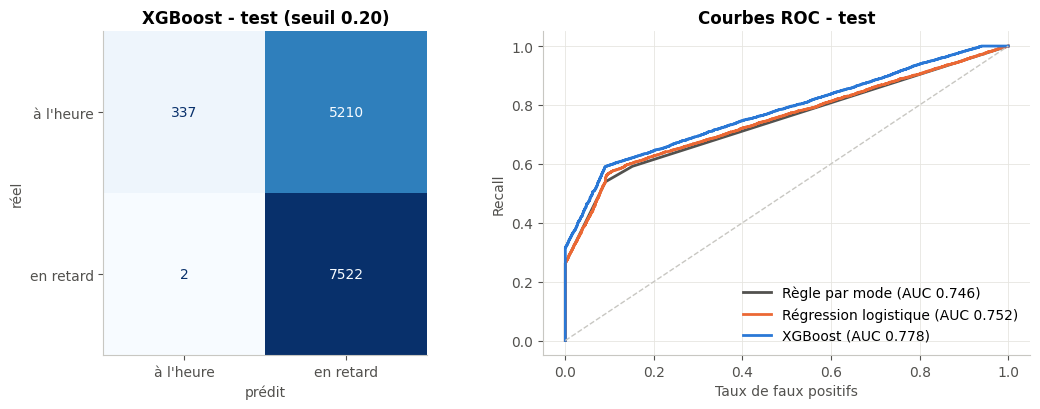

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay.from_predictions(y(test), (proba_test["XGBoost"] >= SEUIL).astype(int),
    display_labels=["à l'heure", "en retard"], cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set(title=f"XGBoost - test (seuil {SEUIL:.2f})", xlabel="prédit", ylabel="réel"); axes[0].grid(False)
for (nom, p), couleur in zip(proba_test.items(), [GRIS, ORANGE, BLEU]):
    fpr, tpr, _ = roc_curve(y(test), p)
    axes[1].plot(fpr, tpr, color=couleur, lw=2, label=f"{nom} (AUC {roc_auc_score(y(test), p):.3f})")
axes[1].plot([0, 1], [0, 1], color="#c8c7c2", ls="--", lw=1)
axes[1].set(title="Courbes ROC - test", xlabel="Taux de faux positifs", ylabel="Recall")
axes[1].legend(loc="lower right", frameon=False)
plt.tight_layout(); plt.show()

In [13]:
# Où le modèle apporte-t-il quelque chose ? AUC par sous-population du test.
def auc_sous_ensemble(masque):
    yy = y(test)[masque]
    if yy.nunique() < 2:
        return np.nan
    return {nom: roc_auc_score(yy, p[masque.values]) for nom, p in proba_test.items()}

sous_ensembles = {
    "Test complet": pd.Series(True, index=test.index),
    "Hors First Class": test["mode_expedition"] != "First Class",
    "Standard + Second Class": test["mode_expedition"].isin(["Standard Class", "Second Class"]),
    "Avant rupture (juil.-sept. 2017)": test["horodatage_commande"] < "2017-10-01",
    "Après rupture (oct. 2017 -> janv. 2018)": test["horodatage_commande"] >= "2017-10-01",
}
auc_detail = pd.DataFrame({k: auc_sous_ensemble(m) for k, m in sous_ensembles.items()}).T
auc_detail.insert(0, "commandes", [int(m.sum()) for m in sous_ensembles.values()])
auc_detail.round(4)

,commandes,Règle par mode,Régression logistique,XGBoost
Test complet,13071,0.7460,0.7519,0.7784
Hors First Class,11097,0.6556,0.6636,0.6995
Standard + Second Class,10366,0.6537,0.6557,0.6556
Avant rupture (juil.-sept. 2017),5028,0.7480,0.7537,0.7763
Après rupture (oct. 2017 -> janv. 2018),8043,0.7447,0.7520,0.7794


## 8. Explicabilité (SHAP)

### 8.1 Importance globale
Les variables catégorielles sont encodées en plusieurs colonnes (one-hot) ; on additionne leurs valeurs SHAP pour revenir à la variable d'origine.

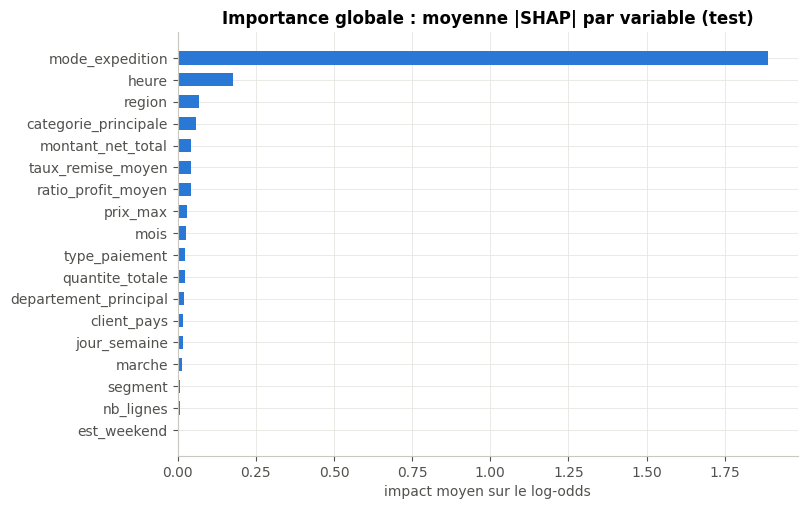

In [14]:
xgb_final = modeles["XGBoost"]
prep, booster = xgb_final.named_steps["prep"], xgb_final.named_steps["modele"]
noms = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]

echantillon = test.sample(3000, random_state=SEED)
X_ech = pd.DataFrame(prep.transform(X(echantillon)), columns=noms, index=echantillon.index)
explainer = shap.TreeExplainer(booster)
valeurs_shap = explainer(X_ech)

def variable_origine(nom):
    return next(v for v in R.VARIABLES if nom == v or nom.startswith(v + "_"))

importance = (pd.Series(np.abs(valeurs_shap.values).mean(0), index=noms)
              .groupby(variable_origine).sum().sort_values())
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(importance.index, importance.values, color=BLEU, height=0.6)
ax.set(title="Importance globale : moyenne |SHAP| par variable (test)", xlabel="impact moyen sur le log-odds")
plt.show()

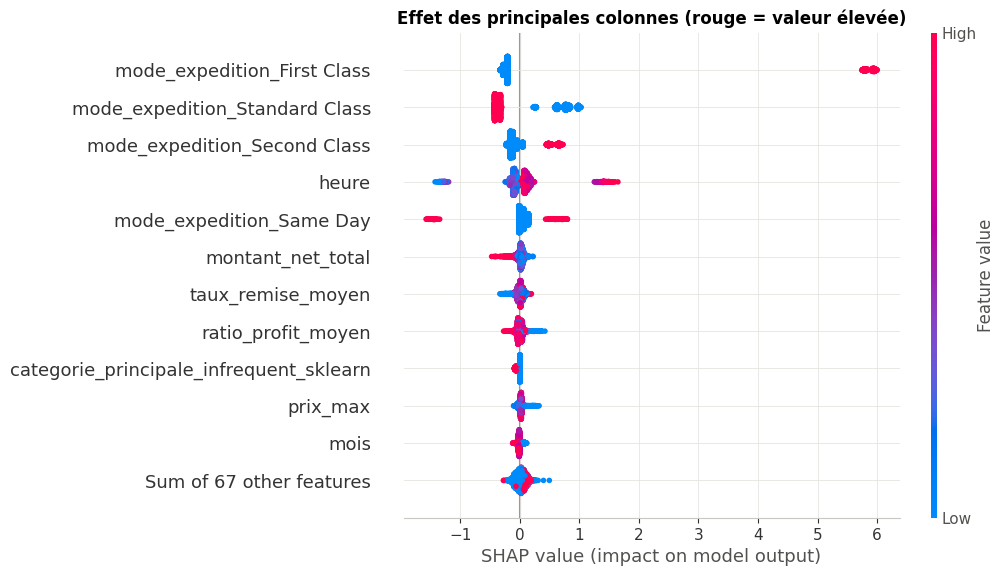

In [15]:
shap.plots.beeswarm(valeurs_shap, max_display=12, show=False)
plt.title("Effet des principales colonnes (rouge = valeur élevée)", fontweight="bold"); plt.show()

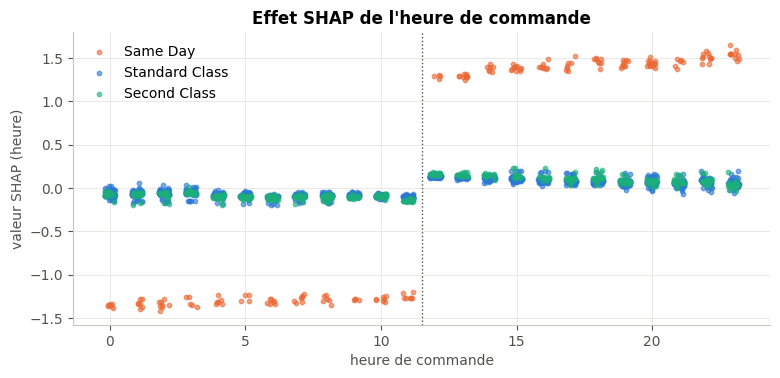

Taux de retard réel Same Day selon l'heure de commande (toutes périodes) :


,mean,size
avant 12 h,0.0,1759
à partir de 12 h,1.0,1648


In [16]:
# La 2e variable est l'heure : regardons son effet par mode.
fig, ax = plt.subplots(figsize=(9, 3.8))
idx_heure = noms.index("heure")
for mode, couleur in [("Same Day", ORANGE), ("Standard Class", BLEU), ("Second Class", AQUA)]:
    m = (echantillon["mode_expedition"] == mode).values
    ax.scatter(echantillon["heure"].values[m] + np.random.uniform(-0.2, 0.2, m.sum()),
               valeurs_shap.values[m, idx_heure], s=10, alpha=0.6, color=couleur, label=mode)
ax.axvline(11.5, color=GRIS, ls=":", lw=1)
ax.set(title="Effet SHAP de l'heure de commande", xlabel="heure de commande", ylabel="valeur SHAP (heure)")
ax.legend(frameon=False); plt.show()

print("Taux de retard réel Same Day selon l'heure de commande (toutes périodes) :")
sd = expediees[expediees["mode_expedition"] == "Same Day"]
sd.groupby(np.where(sd["heure"] < 12, "avant 12 h", "à partir de 12 h"))["est_en_retard"].agg(["mean", "size"]).round(3)

> **Ce que le modèle a appris**
> - Le **mode d'expédition** domine très largement.
> - L'**heure de commande** vient ensuite. Le modèle a découvert seul une **heure limite à midi pour le Same Day** : commandé avant 12 h, jamais en retard ; à partir de 12 h, toujours en retard (l'envoi part le lendemain). C'est une information connue à la commande, donc légitime, et **directement actionnable** : afficher l'heure limite au client, ou basculer automatiquement l'offre « Same Day » sur « Next Day » l'après-midi.
> - Les autres variables (montant, remise, région...) ont un effet faible. Pour Second et Standard Class, le délai réel ne dépend pratiquement de rien d'observable à la commande.

### 8.2 Explications locales : deux commandes Same Day

Commande 66556 (commandée l'après-midi, 13 h) : proba de retard = 0.91, retard réel = 1


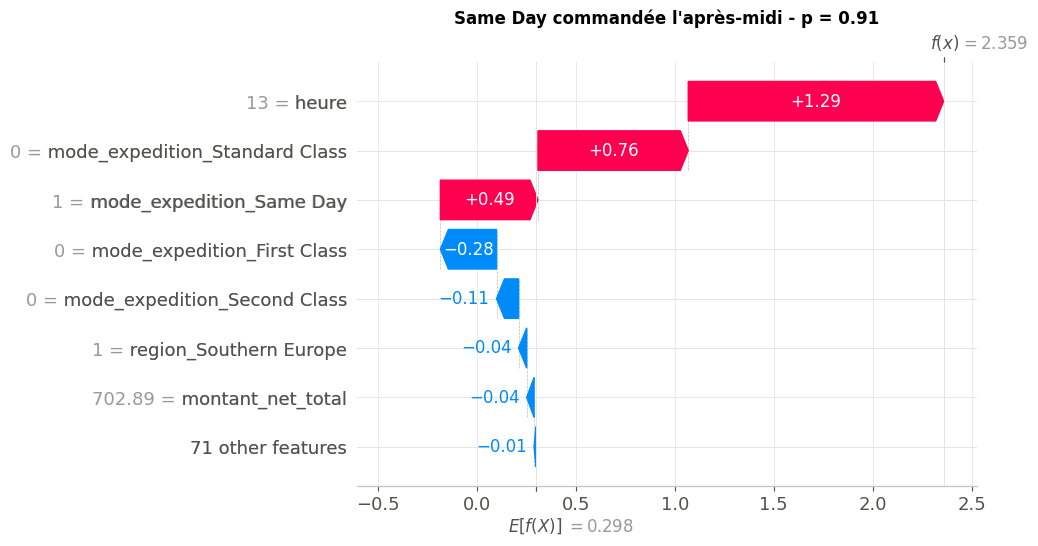

Commande 70235 (commandée le matin, 6 h) : proba de retard = 0.05, retard réel = 0


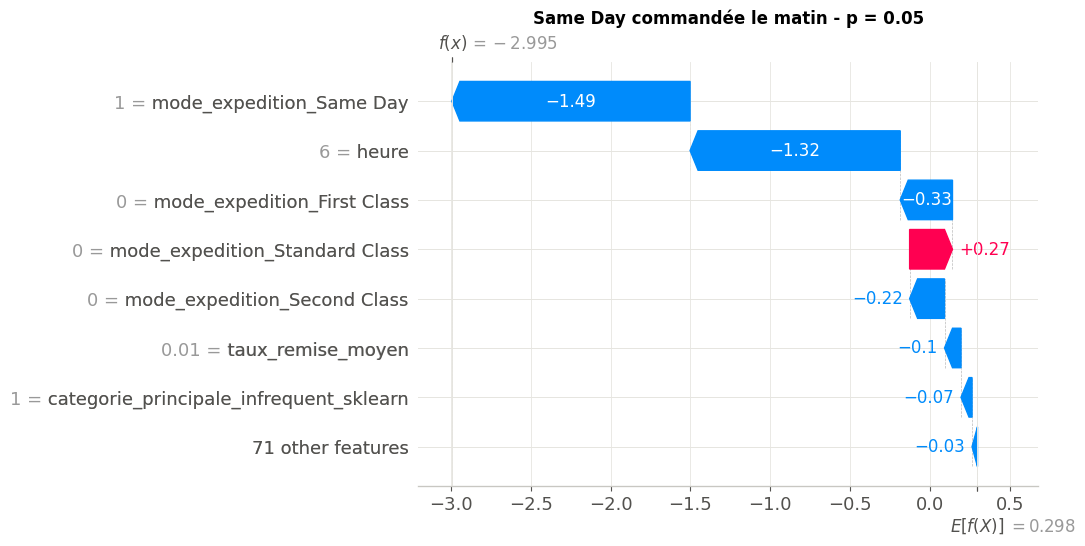

In [17]:
same_day = echantillon[echantillon["mode_expedition"] == "Same Day"]
exemples = {"commandée l'après-midi": same_day[same_day["heure"] >= 12].index[0],
            "commandée le matin": same_day[same_day["heure"] < 12].index[0]}
for titre, idx in exemples.items():
    pos = echantillon.index.get_loc(idx)
    proba = xgb_final.predict_proba(X(echantillon.loc[[idx]]))[0, 1]
    print(f"Commande {echantillon.loc[idx, 'commande_id']} ({titre}, {echantillon.loc[idx, 'heure']} h) : "
          f"proba de retard = {proba:.2f}, retard réel = {echantillon.loc[idx, 'est_en_retard']}")
    shap.plots.waterfall(valeurs_shap[pos], max_display=8, show=False)
    plt.title(f"Same Day {titre} - p = {proba:.2f}", fontweight="bold"); plt.show()

## 9. Le modèle fait-il mieux qu'une règle métier enrichie ?

SHAP a révélé la règle ; on vérifie si une **règle simple** « mode + heure limite Same Day » suffit.
Elle est construite à partir des taux de train + validation et évaluée sur le test.

In [18]:
def profil_regle(d):
    return np.where((d["mode_expedition"] == "Same Day") & (d["heure"] >= 12), "Same Day après-midi", d["mode_expedition"])

taux_profil = y(train_valid).groupby(profil_regle(train_valid)).mean()
p_regle_enrichie = pd.Series(profil_regle(test)).map(taux_profil).to_numpy()
comparaison = pd.DataFrame({
    "ROC-AUC test": {"Règle par mode": roc_auc_score(y(test), proba_test["Règle par mode"]),
                     "Règle mode + heure limite": roc_auc_score(y(test), p_regle_enrichie),
                     "XGBoost": roc_auc_score(y(test), proba_test["XGBoost"])}})
comparaison.round(4)

,ROC-AUC test
Règle par mode,0.7460
Règle mode + heure limite,0.7771
XGBoost,0.7784


## 10. Sauvegarde du modèle et écriture des prédictions

Le modèle sauvegardé est le XGBoost entraîné sur train + validation (celui évalué ci-dessus).
Toutes les commandes sont scorées (y compris les annulées : à la commande, on ne sait pas qu'elle sera annulée).
La colonne `jeu` permet de filtrer dans Power BI : seules les prédictions `test` sont « hors échantillon ».

In [19]:
metriques_test = {k: float(v) for k, v in R.metriques(y(test), proba_test["XGBoost"], SEUIL).items()}
R.sauvegarder(xgb_final, SEUIL, {
    "hyperparametres": params_xgb,
    "couts": {"cout_fn": COUTS.cout_fn, "cout_fp": COUTS.cout_fp},
    "periode_entrainement": [str(train_valid["horodatage_commande"].min()), str(train_valid["horodatage_commande"].max())],
    "metriques_test": metriques_test,
})
modele = R.charger()
print("Modèle sauvegardé :", R.CHEMIN_MODELE.relative_to(RACINE), "| version", modele["version"])

proba_toutes = xgb_final.predict_proba(X(commandes))[:, 1]
predictions = pd.DataFrame({
    "commande_id": commandes["commande_id"],
    "date_commande_id": commandes["horodatage_commande"].dt.strftime("%Y%m%d").astype(int),
    "proba_retard": proba_toutes.round(4),
    "alerte_retard": (proba_toutes >= SEUIL).astype(int),
    "niveau_risque": R.niveau_risque(proba_toutes, SEUIL),
    "seuil": SEUIL,
    "jeu": R.attribuer_jeu(commandes["horodatage_commande"]),
    "est_annulee": commandes["est_annulee"],
    "est_en_retard_reel": commandes["est_en_retard"].where(commandes["est_annulee"] == 0).astype("Int64"),
    "version_modele": modele["version"],
})
executer_script_sql(engine, SQL_DIR / "04_pred_risque.sql")   # crée la table si besoin
with engine.begin() as conn:                                     # vide sans supprimer (les vues bi en dépendent)
    conn.exec_driver_sql("TRUNCATE ml.pred_risque_livraison")
copier_dataframe(engine, predictions, "pred_risque_livraison", schema="ml")
pd.read_sql("SELECT jeu, niveau_risque, COUNT(*) AS commandes, ROUND(AVG(proba_retard), 3) AS proba_moy, "
            "ROUND(AVG(est_en_retard_reel), 3) AS taux_retard_reel "
            "FROM ml.pred_risque_livraison GROUP BY 1, 2 ORDER BY 1, 2", engine)

Modèle sauvegardé : models\risque_xgb.joblib | version risque-xgb-20261124-2218


,jeu,niveau_risque,commandes,proba_moy,taux_retard_reel
0,test,faible,358,0.059,0.006
1,test,moyen,9722,0.462,0.463
2,test,élevé,3590,0.936,0.938
3,train,faible,1224,0.061,0.000
4,train,moyen,29193,0.456,0.451
5,train,élevé,11346,0.931,0.951
6,validation,faible,269,0.059,0.000
7,validation,moyen,7383,0.456,0.450
8,validation,élevé,2667,0.937,0.951


## 11. Conclusions

Voir la cellule suivante pour les chiffres exacts (le texte ne fait que les commenter).

- **XGBoost bat la règle par mode**, mais l'essentiel de ce gain vient d'**une seule règle métier** qu'il a découverte : l'heure limite de midi du Same Day. Une règle « mode + heure limite » obtient pratiquement la même performance. En production, on peut donc proposer l'une ou l'autre ; XGBoost a l'avantage de capter automatiquement de futures règles de ce type.
- Pour **Second et Standard Class** (80 % des commandes), le retard est quasi imprévisible avec les informations disponibles à la commande : le délai réel semble tiré au hasard entre 2 et 6 jours.
- Le modèle reste **stable après la rupture** d'octobre 2017, car il s'appuie sur des variables qui ne changent pas avec le catalogue.
- **Recommandation métier** : le problème principal n'est pas prédictif mais **contractuel**. First Class promet 1 jour et livre toujours en 2 ; Second Class promet 2 jours pour un délai réel de 2 à 6. Revoir les délais affichés réduirait plus les retards que n'importe quel modèle.

In [20]:
print("Hyperparamètres XGBoost :", params_xgb, "| C régression logistique :", meilleur_C, "| seuil :", SEUIL)
display(resultats_test[["roc_auc", "pr_auc", "brier", "recall", "precision", "f1", "taux_alerte"]].astype(float).round(4))
display(comparaison.round(4))

Hyperparamètres XGBoost : {'max_depth': 3, 'learning_rate': 0.05, 'n_estimators': 500} | C régression logistique : 10.0 | seuil : 0.2


,roc_auc,pr_auc,brier,recall,precision,f1,taux_alerte
Règle par mode,0.7460,0.7878,0.1874,1.0000,0.5756,0.7307,1.0000
Régression logistique,0.7519,0.8418,0.1874,1.0000,0.5756,0.7307,1.0000
XGBoost,0.7784,0.8593,0.1747,0.9997,0.5908,0.7427,0.9741


,ROC-AUC test
Règle par mode,0.7460
Règle mode + heure limite,0.7771
XGBoost,0.7784
